# Toyota Camry Auction Price Prediction

Predicting used Toyota Camry (model years 2020–2026) auction sale prices in USD at Copart and IAAI, using vehicle specifications, mileage, seller information and damage data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.compose import ColumnTransformer

SEED = 509

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

## 1. Load the data

In [2]:
df = pd.read_csv("final_dataset.csv")

In [3]:
df_camry = df[(df["model"] == "CAMRY") & (df["year"] > 2019)]
# make_model_year_price_median is computed from the sale prices themselves, so keeping it would leak the target
df_camry = df_camry.drop(columns=["detail_url", "make", "model", "photo_urls_json", "make_model_year_price_median"])
df_camry.nunique()

vin                          2681
seller_type                     2
auction                         2
sale_date                     384
sold_price                    454
currency                        2
year                            7
mileage                      2515
engine_volume                   2
cylinders                       2
fuel_type                       4
transmission                    3
drive_type                      3
primary_damage                 24
primary_damage_severity         8
secondary_damage               25
secondary_damage_severity       8
dtype: int64

In [4]:
df_camry.describe(include="all")

,vin,seller_type,auction,sale_date,sold_price,currency,year,mileage,engine_volume,cylinders,fuel_type,transmission,drive_type,primary_damage,primary_damage_severity,secondary_damage,secondary_damage_severity
count,2681,2681,2681,2681,2681.000000,2681,2681.000000,2572.000000,2673.000000,2673.000000,2681,2681,2681,2681,2015.000000,1792,1632.000000
unique,2681,2,2,384,NaN,2,NaN,NaN,NaN,NaN,4,3,3,24,NaN,25,NaN
top,4T1G11AK7MU419412,Insurance,copart,01/15/2026 18:00 UTC,NaN,USD,NaN,NaN,NaN,NaN,GAS,AUTOMATIC,FWD,FRONT END,NaN,FRONT END,NaN
freq,1,2284,1685,36,NaN,2673,NaN,NaN,NaN,NaN,1745,2657,2438,1389,NaN,607,NaN
mean,NaN,NaN,NaN,NaN,9370.635957,NaN,2022.611712,59222.774495,2.535166,4.070333,NaN,NaN,NaN,NaN,3.756079,NaN,3.359681
std,NaN,NaN,NaN,NaN,4078.566802,NaN,1.888772,51256.523403,0.184235,0.368470,NaN,NaN,NaN,NaN,0.488885,NaN,0.720365
min,NaN,NaN,NaN,NaN,100.000000,NaN,2020.000000,1.000000,2.500000,4.000000,NaN,NaN,NaN,NaN,1.000000,NaN,1.000000
25%,NaN,NaN,NaN,NaN,6500.000000,NaN,2021.000000,23485.750000,2.500000,4.000000,NaN,NaN,NaN,NaN,3.500000,NaN,3.000000
50%,NaN,NaN,NaN,NaN,8500.000000,NaN,2023.000000,51319.500000,2.500000,4.000000,NaN,NaN,NaN,NaN,4.000000,NaN,3.500000
75%,NaN,NaN,NaN,NaN,11900.000000,NaN,2025.000000,81995.250000,2.500000,4.000000,NaN,NaN,NaN,NaN,4.000000,NaN,4.000000


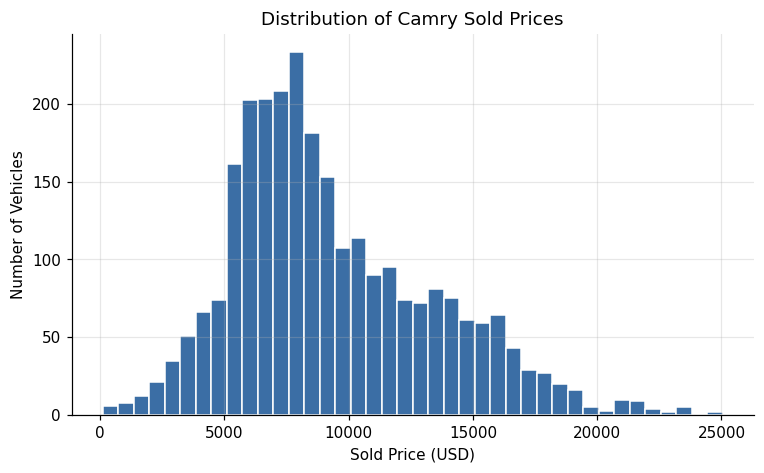

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_camry["sold_price"], bins=40, color="#3b6ea5", edgecolor="white")
ax.set(title="Distribution of Camry Sold Prices", xlabel="Sold Price (USD)", ylabel="Number of Vehicles")
plt.show()

## 2. Data cleaning

In [6]:
df_camry = df_camry.drop_duplicates(subset=["vin"])
df_camry.shape

(2681, 17)

### Fuel type and drive type from the VIN
`fuel_type = OTHER` (343 cars) sold at hybrid-level prices, and some fuel and drive values are `UNKNOWN`. Characters 5–7 of a Toyota VIN encode the powertrain. The crosstab shows every "OTHER" car has a hybrid powertrain code, and each code belongs to exactly one fuel type, drive type and engine size. The unreliable labels are therefore replaced with the label that matches the VIN code.

In [7]:
df_camry["vin_code"] = df_camry["vin"].str[4:7]
pd.crosstab(df_camry["vin_code"], df_camry["fuel_type"])

fuel_type,GAS,HYBRID ENGINE,OTHER,UNKNOWN
vin_code,,,,
11A,1311,0,0,2
11B,107,0,0,1
31A,0,164,88,1
61A,203,0,0,0
61B,30,0,0,0
AAC,0,350,227,4
BAD,0,68,30,0
Z1A,94,0,0,1


In [8]:
for column, unreliable in [("fuel_type", ["OTHER", "UNKNOWN"]), ("drive_type", ["UNKNOWN"]), ("engine_volume", [])]:
    reliable = df_camry[df_camry[column].notna() & ~df_camry[column].isin(unreliable)]
    code_to_label = reliable.groupby("vin_code")[column].agg(lambda s: s.mode().iloc[0])
    df_camry[column] = df_camry["vin_code"].map(code_to_label).fillna(df_camry[column])

df_camry["fuel_type"] = df_camry["fuel_type"].replace({"HYBRID ENGINE": "HYBRID"})
pd.crosstab(df_camry["vin_code"], df_camry["fuel_type"])

fuel_type,GAS,HYBRID
vin_code,,
11A,1313,0
11B,108,0
31A,0,253
61A,203,0
61B,30,0
AAC,0,581
BAD,0,98
Z1A,95,0


In [9]:
df_camry = df_camry.drop(columns=["vin", "vin_code"])

In [10]:
df_camry.insert(0, 'sale_date', df_camry.pop('sale_date'))

In [11]:
cad_to_usd = 0.713508

df_camry["sold_price"] = df_camry["sold_price"].astype(float)

mask = df_camry["currency"] == "CAD"

df_camry.loc[mask, "sold_price"] = df_camry.loc[mask, "sold_price"] * cad_to_usd

# round to whole dollars (astype(int) alone would cut off the cents)
df_camry["sold_price"] = df_camry["sold_price"].round().astype(int)

df_camry = df_camry.drop(columns=["currency"])

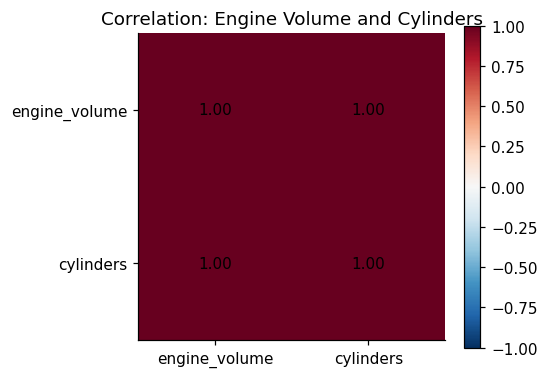

In [12]:
corr_matrix = df_camry[["engine_volume", "cylinders"]].corr()

fig, ax = plt.subplots(figsize=(4.5, 3.8))
image = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.index)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")
ax.grid(False)
fig.colorbar(image, ax=ax)
ax.set_title("Correlation: Engine Volume and Cylinders")
plt.show()

In [13]:
df_camry = df_camry.drop(columns=["cylinders"])

In [14]:
df_camry.head()

,sale_date,seller_type,auction,sold_price,year,mileage,engine_volume,fuel_type,transmission,drive_type,primary_damage,primary_damage_severity,secondary_damage,secondary_damage_severity
335,03/06/2026 17:00 UTC,Insurance,iaai,6600,2021,76491.0,2.5,GAS,AUTOMATIC,FWD,FRONT END,3.5,FRONT END,4.0
515,03/06/2026 18:00 UTC,Insurance,copart,5500,2023,55536.0,2.5,GAS,AUTOMATIC,FWD,FRONT END,4.0,NaN,NaN
649,03/06/2026 18:00 UTC,Insurance,copart,10500,2020,54505.0,3.5,GAS,AUTOMATIC,FWD,REAR END,4.0,MINOR DENT/SCRATCHES,4.0
997,03/06/2026 15:00 UTC,Insurance,copart,6000,2025,NaN,2.5,HYBRID,AUTOMATIC,AWD,REAR END,4.0,SIDE,4.0
1073,03/06/2026 20:00 UTC,Insurance,copart,5500,2022,89059.0,2.5,GAS,AUTOMATIC,FWD,FRONT END,4.0,UNDERCARRIAGE,3.5


In [15]:
df_camry["fuel_type"].value_counts(ascending=False)

fuel_type
GAS       1749
HYBRID     932
Name: count, dtype: int64

`drive_type` is kept as a feature: after the VIN fix there are no `UNKNOWN` values, and AWD cars sell for more than FWD cars.

In [16]:
df_camry["drive_type"].value_counts(ascending=False)

drive_type
FWD    2445
AWD     236
Name: count, dtype: int64

In [17]:
df_camry.groupby("transmission").size().sort_values(ascending=False)

transmission
AUTOMATIC    2657
UNKNOWN        23
MANUAL          1
dtype: int64

Every 2020+ Camry is automatic, so `transmission` carries no information. The `UNKNOWN` rows are real cars, so only the column is dropped, not the rows.

In [18]:
df_camry = df_camry.drop(columns=["transmission"])

In [19]:
df_camry["primary_damage_severity"].value_counts(dropna=False)

primary_damage_severity
4.0    1200
NaN     666
3.5     466
3.0     155
4.5     108
2.5      46
2.0      25
1.5      13
1.0       2
Name: count, dtype: int64

In [20]:
df_camry["primary_damage"].value_counts(dropna=False)

primary_damage
FRONT END               1389
REAR END                 548
SIDE                     417
FRONT & REAR              95
ALL OVER                  50
ROLLOVER                  33
HAIL                      32
WATER/FLOOD               22
MINOR DENT/SCRATCHES      21
UNDERCARRIAGE             15
NORMAL WEAR & TEAR        12
MECHANICAL                10
BURN                       8
VANDALISM                  6
ROOF                       5
BIOHAZARD                  5
BURN - ENGINE              3
THEFT                      3
STORM DAMAGE               2
DAMAGE HISTORY             1
REPOSSESSION               1
FRAME DAMAGE               1
SUSPENSION                 1
ENGINE DAMAGE              1
Name: count, dtype: int64

In [21]:
low_count_damage = df_camry["primary_damage"].value_counts()
df_camry.loc[
    df_camry["primary_damage"].isin(low_count_damage[low_count_damage < 20].index),
    "primary_damage"
] = "OTHER"

In [22]:
df_camry["secondary_damage_severity"].value_counts(dropna=False)

secondary_damage_severity
NaN    1049
4.0     549
3.5     510
3.0     255
2.5     136
2.0      71
1.5      64
4.5      32
1.0      15
Name: count, dtype: int64

In [23]:
df_camry["secondary_damage"].value_counts(dropna=False)

secondary_damage
NaN                     889
FRONT END               607
SIDE                    444
REAR END                399
FRONT & REAR             95
MINOR DENT/SCRATCHES     62
UNDERCARRIAGE            52
HAIL                     29
MECHANICAL               21
ROOF                     14
ROLLOVER                 14
ALL OVER                 11
WATER/FLOOD              10
NORMAL WEAR & TEAR        6
BIOHAZARD                 5
BURN                      4
VANDALISM                 4
FRAME DAMAGE              3
THEFT                     3
STORM DAMAGE              2
STRIPPED                  2
REJECTED REPAIR           1
BURN - ENGINE             1
REPOSSESSION              1
SUSPENSION                1
ENGINE DAMAGE             1
Name: count, dtype: int64

In [24]:
pd.crosstab(
    df_camry["secondary_damage"].isna(),
    df_camry["secondary_damage_severity"].isna(),
    rownames=["Damage missing"],
    colnames=["Severity missing"]
)

Severity missing,False,True
Damage missing,,
False,1632,160
True,0,889


In [25]:
df_camry["secondary_damage"] = (df_camry["secondary_damage"].fillna("NOT_RECORDED"))
low_count_damage = df_camry["secondary_damage"].value_counts()
df_camry.loc[
    df_camry["secondary_damage"].isin(low_count_damage[low_count_damage < 20].index),
    "secondary_damage"
] = "OTHER"

In [26]:
df_camry["secondary_damage"].value_counts(dropna=False)

secondary_damage
NOT_RECORDED            889
FRONT END               607
SIDE                    444
REAR END                399
FRONT & REAR             95
OTHER                    83
MINOR DENT/SCRATCHES     62
UNDERCARRIAGE            52
HAIL                     29
MECHANICAL               21
Name: count, dtype: int64

In [27]:
df_camry.nunique()

sale_date                     384
seller_type                     2
auction                         2
sold_price                    462
year                            7
mileage                      2515
engine_volume                   2
fuel_type                       2
drive_type                      2
primary_damage                 10
primary_damage_severity         8
secondary_damage               10
secondary_damage_severity       8
dtype: int64

### Mileage placeholders
`1` and `999999` are placeholders for an unreadable odometer. They are set to missing instead of dropping the car; the pipeline's median imputer fills them and `add_indicator=True` marks them.

In [28]:
placeholder = df_camry["mileage"].isin([1, 999999])
df_camry.loc[placeholder, "mileage"] = np.nan
print(f"Mileage placeholders set to missing: {placeholder.sum()}")

Mileage placeholders set to missing: 32


### Very low sale prices
Sales under $1,000 are burned, rolled-over or flooded wrecks sold for scrap, which is a different market. They are removed.

In [29]:
low_price = df_camry["sold_price"] < 1000
print(f"Removed {low_price.sum()} sales under $1,000")
df_camry = df_camry[~low_price].copy()
df_camry.shape

Removed 9 sales under $1,000


(2672, 13)

In [30]:
df_camry["sale_date"] = pd.to_datetime(
    df_camry["sale_date"],
    format="%m/%d/%Y %H:%M %Z",
    utc=True,
    errors="raise"
)

df_camry = df_camry.sort_values("sale_date").reset_index(drop=True)
df_camry.head()

,sale_date,seller_type,auction,sold_price,year,mileage,engine_volume,fuel_type,drive_type,primary_damage,primary_damage_severity,secondary_damage,secondary_damage_severity
0,2025-12-23 14:30:00+00:00,Insurance,iaai,13250,2023,10964.0,2.5,GAS,FWD,FRONT END,4.5,FRONT END,4.0
1,2025-12-23 15:00:00+00:00,Seller,copart,8300,2021,114623.0,2.5,GAS,FWD,FRONT END,3.5,SIDE,2.5
2,2025-12-23 15:00:00+00:00,Insurance,copart,8800,2024,30368.0,2.5,GAS,FWD,FRONT END,4.0,NOT_RECORDED,NaN
3,2025-12-23 15:00:00+00:00,Insurance,copart,10900,2022,59171.0,2.5,GAS,FWD,FRONT END,4.0,SIDE,4.0
4,2025-12-23 15:00:00+00:00,Insurance,copart,4450,2020,76440.0,2.5,GAS,FWD,REAR END,4.0,SIDE,3.5


## 3. Exploring price drivers

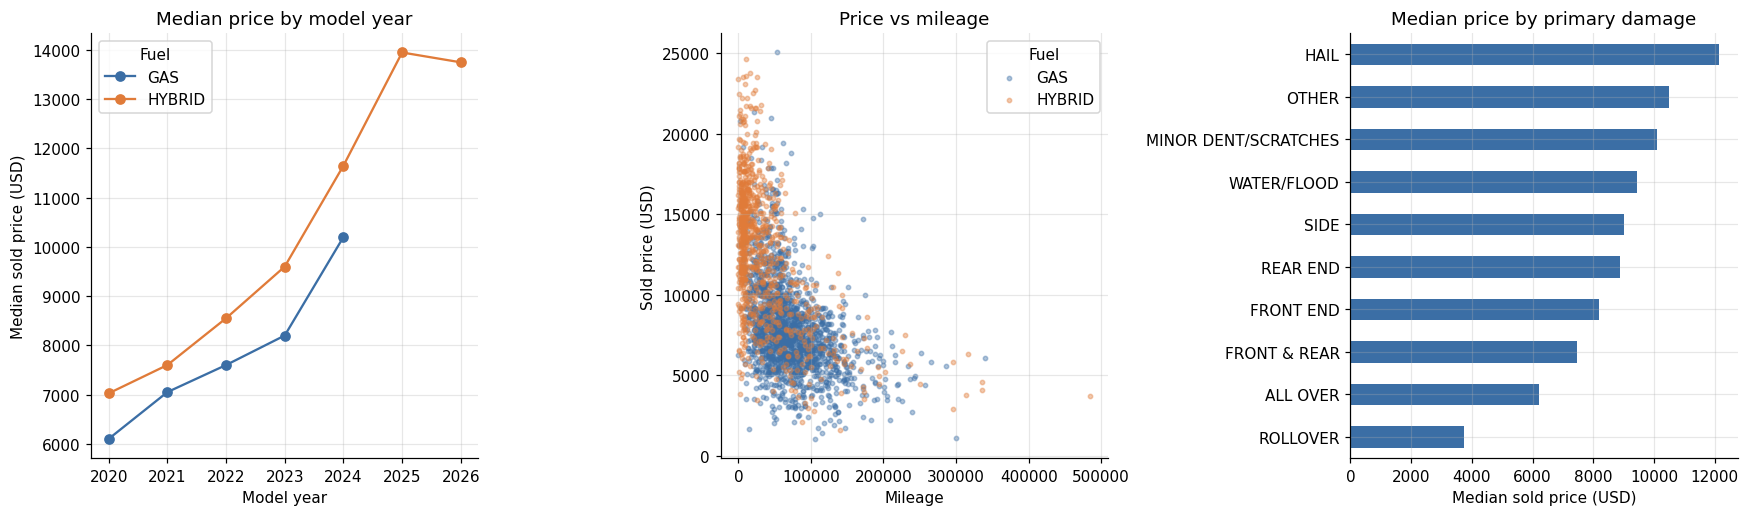

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
by_year = df_camry.groupby(["year", "fuel_type"])["sold_price"].median().unstack()
by_year.plot(ax=ax, marker="o", color={"GAS": "#3b6ea5", "HYBRID": "#e07b39"})
ax.set(title="Median price by model year", xlabel="Model year", ylabel="Median sold price (USD)")
ax.legend(title="Fuel")

ax = axes[1]
for fuel, color in [("GAS", "#3b6ea5"), ("HYBRID", "#e07b39")]:
    part = df_camry[df_camry["fuel_type"] == fuel]
    ax.scatter(part["mileage"], part["sold_price"], s=8, alpha=0.4, color=color, label=fuel)
ax.set(title="Price vs mileage", xlabel="Mileage", ylabel="Sold price (USD)")
ax.legend(title="Fuel")

ax = axes[2]
(df_camry.groupby("primary_damage")["sold_price"].median()
    .sort_values()
    .plot.barh(ax=ax, color="#3b6ea5"))
ax.set(title="Median price by primary damage", xlabel="Median sold price (USD)", ylabel="")

fig.tight_layout()
fig.savefig(IMAGES / "eda_overview.png", bbox_inches="tight")
plt.show()

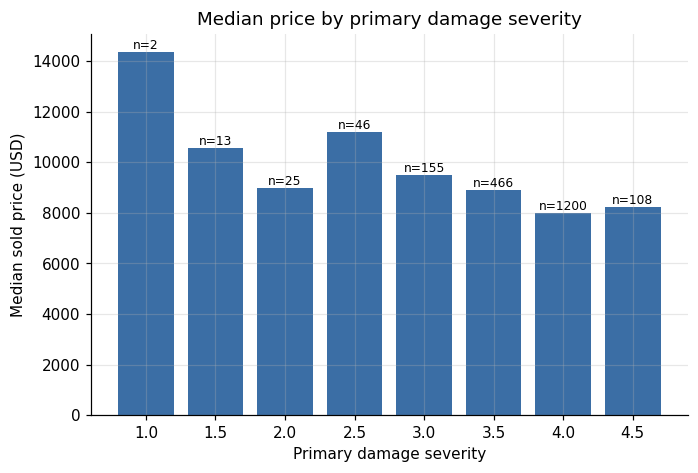

In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5))
severity = df_camry.groupby("primary_damage_severity")["sold_price"].agg(["median", "size"])
ax.bar(severity.index.astype(str), severity["median"], color="#3b6ea5")
for x, (med, n) in enumerate(zip(severity["median"], severity["size"])):
    ax.text(x, med, f"n={n}", ha="center", va="bottom", fontsize=8)
ax.set(title="Median price by primary damage severity", xlabel="Primary damage severity", ylabel="Median sold price (USD)")
fig.savefig(IMAGES / "price_by_severity.png", bbox_inches="tight")
plt.show()

## 4. Train / validation / test split and preprocessing

In [33]:
X = df_camry.drop(columns=["sold_price", "sale_date"])
y = df_camry["sold_price"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)


In [34]:
numeric_features = [
    "year",
    "mileage",
    "engine_volume",
    "primary_damage_severity",
    "secondary_damage_severity"
]

categorical_features = [
    "seller_type",
    "auction",
    "fuel_type",
    "drive_type",
    "primary_damage",
    "secondary_damage"
]

In [35]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [36]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 5. Models: Linear Regression, Ridge and Lasso

In [37]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
models = {
    "Linear Regression": linear_pipeline,
    "Ridge": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Lasso(alpha=1.0, max_iter=10000))
    ])
}

results = []

for name, model in models.items():
    # Linear Regression was already fitted
    if name != "Linear Regression":
        model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": mean_squared_error(y_val, predictions) ** 0.5,
        "R²": r2_score(y_val, predictions)
    })

comparison = pd.DataFrame(results).sort_values("MAE")
comparison

,Model,MAE,RMSE,R²
2,Lasso,1978.057079,2556.361328,0.565010
1,Ridge,1978.283884,2555.113404,0.565435
0,Linear Regression,1980.407108,2557.858470,0.564501


In [39]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=50000)
}

scores = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    scores[name] = {
        "MAE": -result["test_MAE"].mean(),
        "RMSE": -result["test_RMSE"].mean(),
        "R2": result["test_R2"].mean()
    }

pd.DataFrame(scores).T.round(3)

,MAE,RMSE,R2
Linear,1937.053,2558.189,0.607
Ridge,1935.341,2557.285,0.608
Lasso,1934.564,2556.279,0.608


In [40]:
alphas = np.logspace(-3, 4, 20)

results = {}

for name, model in {
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=50000)
}.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid={"model__alpha": alphas},
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    results[name] = search

    print(f"{name}")
    print("Best alpha:", search.best_params_["model__alpha"])
    print("Best CV MAE:", -search.best_score_)

Ridge
Best alpha: 2.069138081114788
Best CV MAE: 1934.0783510749447


Lasso
Best alpha: 4.832930238571752
Best CV MAE: 1931.3766792587753


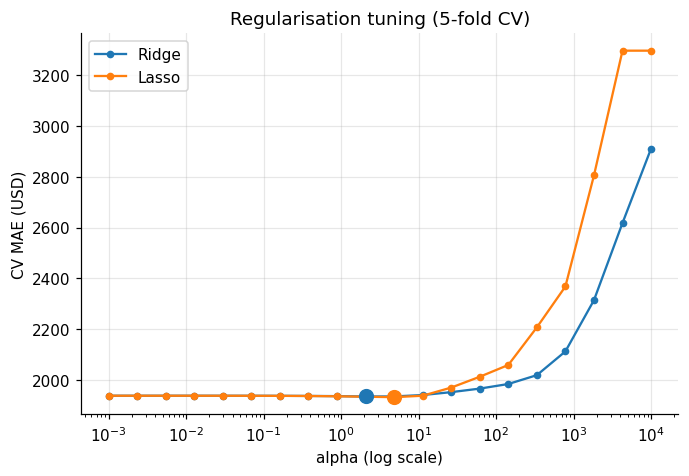

In [41]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, search in results.items():
    ax.plot(alphas, -search.cv_results_["mean_test_score"], marker="o", markersize=4, label=name)
    ax.scatter(search.best_params_["model__alpha"], -search.best_score_, s=80, zorder=3)
ax.set_xscale("log")
ax.set(title="Regularisation tuning (5-fold CV)", xlabel="alpha (log scale)", ylabel="CV MAE (USD)")
ax.legend()
fig.savefig(IMAGES / "regularisation_tuning.png", bbox_inches="tight")
plt.show()

In [42]:
validation_models = {
    "Linear Regression": linear_pipeline,
    "Ridge": results["Ridge"].best_estimator_,
    "Lasso": results["Lasso"].best_estimator_
}

validation_results = []

for name, model in validation_models.items():
    predictions = model.predict(X_val)

    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": mean_squared_error(y_val, predictions) ** 0.5,
        "R²": r2_score(y_val, predictions)
    })

validation_comparison = (
    pd.DataFrame(validation_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

validation_comparison.round(3)

,Model,MAE,RMSE,R²
0,Lasso,1973.235,2557.002,0.565
1,Ridge,1976.441,2553.390,0.566
2,Linear Regression,1980.407,2557.858,0.565


## 6. Final evaluation on the test set

In [43]:
best_name = validation_comparison.iloc[0]["Model"]
final_pipeline = clone(validation_models[best_name])

# Combine training and validation data
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Refit preprocessing and model together
final_pipeline.fit(X_train_val, y_train_val)

# Final evaluation on untouched test data
test_predictions = final_pipeline.predict(X_test)

print(f"Selected model: {best_name}")
print(f"Test MAE:  ${mean_absolute_error(y_test, test_predictions):,.2f}")
print(f"Test RMSE: ${mean_squared_error(y_test, test_predictions) ** 0.5:,.2f}")
print(f"Test R²:   {r2_score(y_test, test_predictions):.3f}")

Selected model: Lasso
Test MAE:  $2,000.79
Test RMSE: $2,569.52
Test R²:   0.600


## 7. Result visualisations

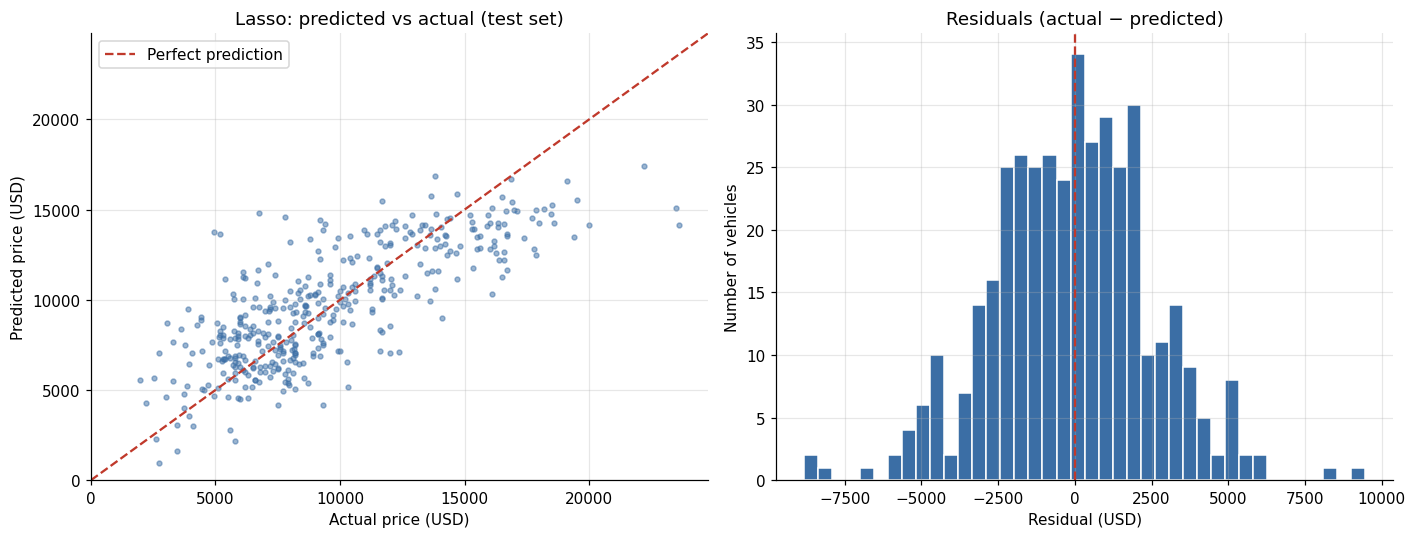

In [44]:
residuals = y_test - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.scatter(y_test, test_predictions, s=10, alpha=0.5, color="#3b6ea5")
limit = [0, max(y_test.max(), test_predictions.max()) * 1.05]
ax.plot(limit, limit, color="#c0392b", linestyle="--", label="Perfect prediction")
ax.set(xlim=limit, ylim=limit, xlabel="Actual price (USD)", ylabel="Predicted price (USD)",
       title=f"{best_name}: predicted vs actual (test set)")
ax.legend()

ax = axes[1]
ax.hist(residuals, bins=40, color="#3b6ea5", edgecolor="white")
ax.axvline(0, color="#c0392b", linestyle="--")
ax.set(title="Residuals (actual − predicted)", xlabel="Residual (USD)", ylabel="Number of vehicles")

fig.tight_layout()
fig.savefig(IMAGES / "predicted_vs_actual.png", bbox_inches="tight")
plt.show()

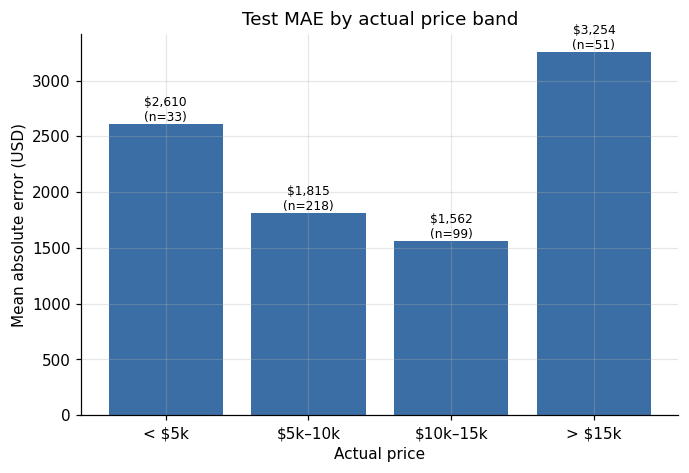

In [45]:
price_band = pd.cut(y_test, [0, 5000, 10000, 15000, np.inf], labels=["< $5k", "$5k–10k", "$10k–15k", "> $15k"])
error_by_band = (pd.DataFrame({"price_band": price_band, "abs_error": residuals.abs()})
                 .groupby("price_band", observed=True)["abs_error"].agg(["mean", "size"]))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(error_by_band.index.astype(str), error_by_band["mean"], color="#3b6ea5")
for x, (mae, n) in enumerate(zip(error_by_band["mean"], error_by_band["size"])):
    ax.text(x, mae, f"${mae:,.0f}\n(n={n})", ha="center", va="bottom", fontsize=8)
ax.set(title="Test MAE by actual price band", xlabel="Actual price", ylabel="Mean absolute error (USD)")
fig.savefig(IMAGES / "error_by_price_band.png", bbox_inches="tight")
plt.show()

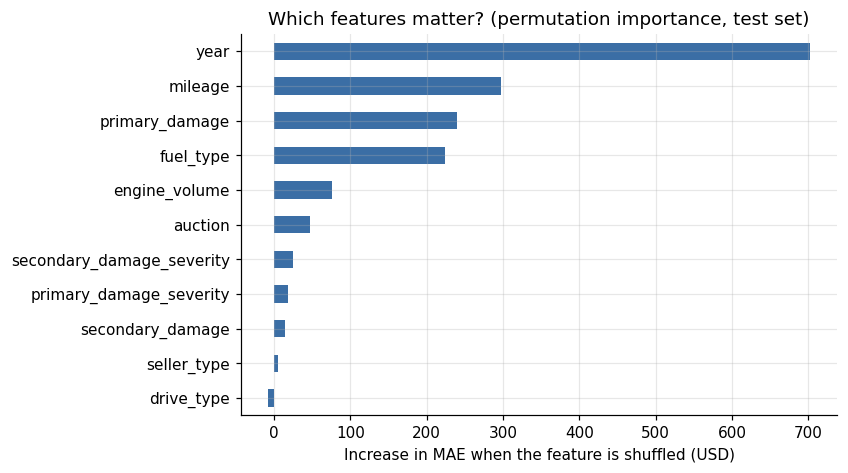

In [46]:
importance = permutation_importance(
    final_pipeline, X_test, y_test,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEED,
)
importance = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
importance.plot.barh(ax=ax, color="#3b6ea5")
ax.set(title="Which features matter? (permutation importance, test set)",
       xlabel="Increase in MAE when the feature is shuffled (USD)")
fig.savefig(IMAGES / "feature_importance.png", bbox_inches="tight")
plt.show()

## 8. Conclusions

- **Lasso (alpha ≈ 4.8) was selected on validation**, then refitted on train + validation. On the untouched test set: **MAE $2,001, RMSE $2,570, R² 0.600** (the previous version of this notebook scored R² 0.585).
- Linear Regression, Ridge and Lasso perform almost identically. With around 30 encoded features and 2,600 cars, regularisation barely changes the fit (see the tuning curve).
- **Model year matters most**, followed by mileage, primary damage type and fuel type. Seller type and drive type add almost nothing once the other features are known.
- The model pulls extreme prices toward the middle: errors are smallest for $5k–15k cars and largest for cars above $15k and below $5k.

**Limitations:** a random split mixes sales from the same weeks into training and test, so this is not a forecast of future auctions. Trim level, title type and real condition are not in the data and probably explain much of the remaining error.